In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
from google.colab import files
uploaded = files.upload()

Saving loan_approval_data.csv to loan_approval_data.csv


In [3]:
df = pd.read_csv("loan_approval_data.csv")
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

In [4]:
df.isnull().sum()

,0
Applicant_ID,50
Applicant_Income,50
Coapplicant_Income,50
Employment_Status,50
Age,50
Marital_Status,50
Dependents,50
Credit_Score,50
Existing_Loans,50
DTI_Ratio,50


In [5]:
# ERADICATE THE MISSING VALUES

df = df.dropna(subset=["Loan_Approved"])

categorical_cols = df.select_dtypes(include=["object"]).columns
numerical_cols = df.select_dtypes(include=["number"]).columns

from sklearn.impute import SimpleImputer

num_imp = SimpleImputer(strategy="mean")
df[numerical_cols] = num_imp.fit_transform(df[numerical_cols])

cat_imp = SimpleImputer(strategy="most_frequent")
df[categorical_cols] = cat_imp.fit_transform(df[categorical_cols])

df = df.drop("Applicant_ID", axis=1)

print(df.shape)
df.isnull().sum().sum()

(950, 19)


np.int64(0)

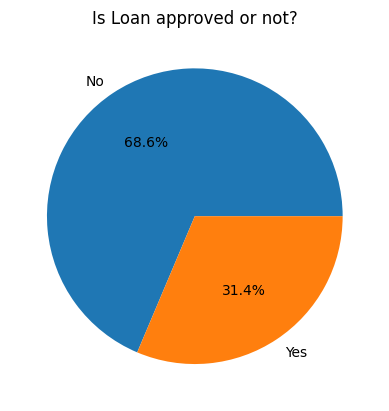

In [6]:
# EXPLORATORY DATA ANALYSIS

classes_count = df["Loan_Approved"].value_counts()

plt.pie(classes_count, labels=classes_count.index, autopct="%1.1f%%")
plt.title("Is Loan approved or not?")
plt.show()

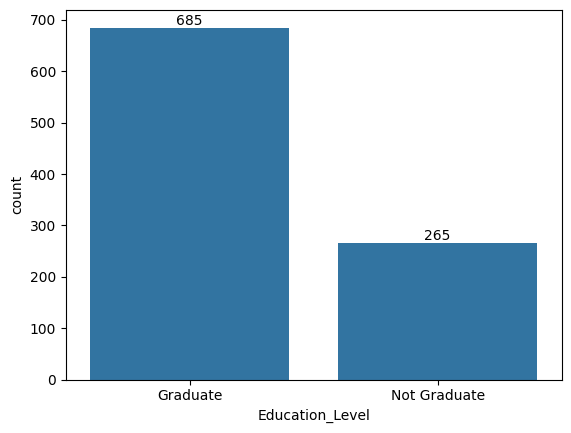

In [7]:
edu_cnt = df["Education_Level"].value_counts()
ax = sns.barplot(edu_cnt)
ax.bar_label(ax.containers[0])
plt.show()

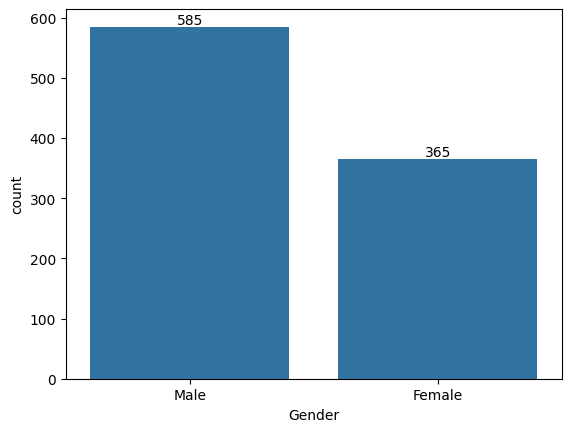

In [8]:
gender_cnt = df["Gender"].value_counts()
ax = sns.barplot(gender_cnt)
ax.bar_label(ax.containers[0])
plt.show()

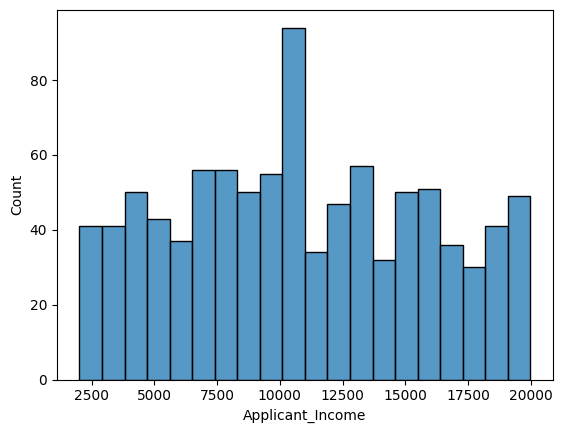

In [9]:
sns.histplot(data=df, x="Applicant_Income", bins=20)
plt.show()

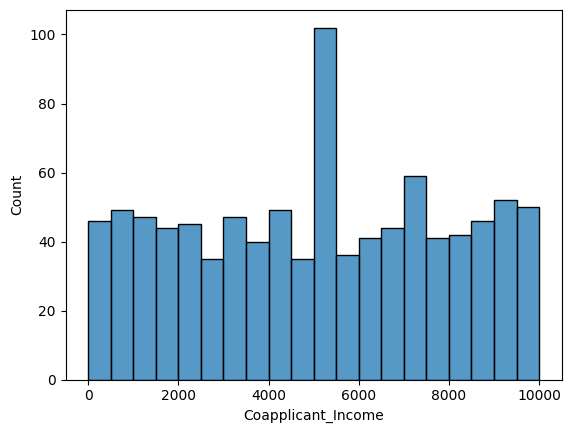

In [10]:
sns.histplot(data=df, x="Coapplicant_Income", bins=20)
plt.show()

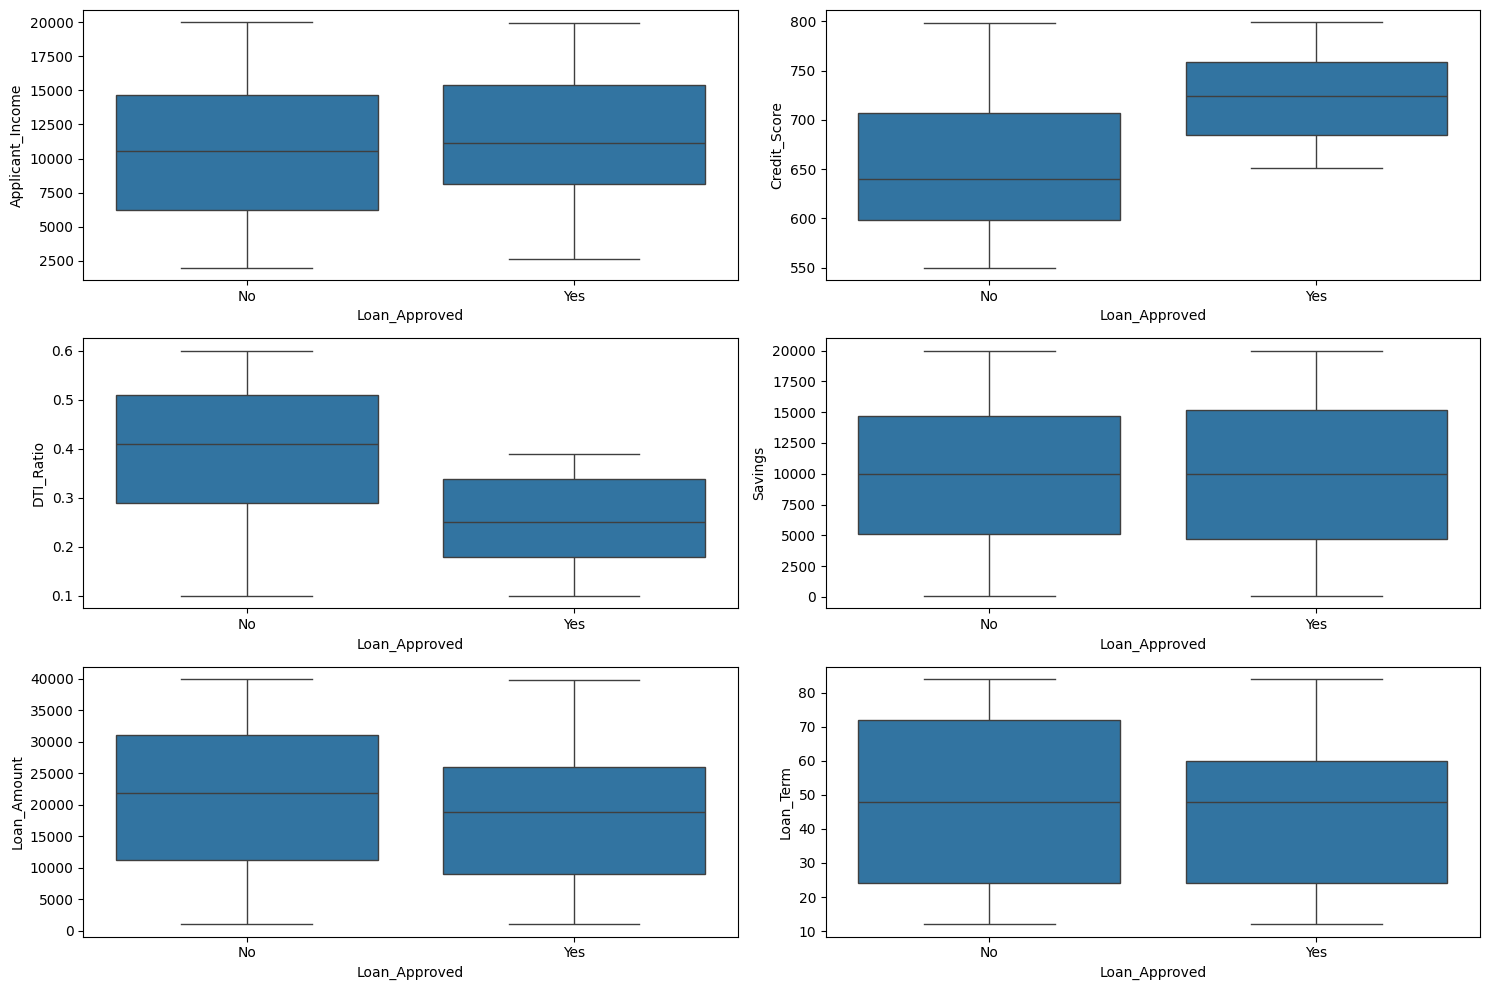

In [11]:
# OUTLIERS - BOXPLOT

fig, axes = plt.subplots(3, 2, figsize=(15, 10))

sns.boxplot(ax=axes[0, 0], data=df, x="Loan_Approved", y="Applicant_Income")
sns.boxplot(ax=axes[0, 1], data=df, x="Loan_Approved", y="Credit_Score")
sns.boxplot(ax=axes[1, 0], data=df, x="Loan_Approved", y="DTI_Ratio")
sns.boxplot(ax=axes[1, 1], data=df, x="Loan_Approved", y="Savings")
sns.boxplot(ax=axes[2, 0], data=df, x="Loan_Approved", y="Loan_Amount")
sns.boxplot(ax=axes[2, 1], data=df, x="Loan_Approved", y="Loan_Term")

plt.tight_layout()
plt.show()

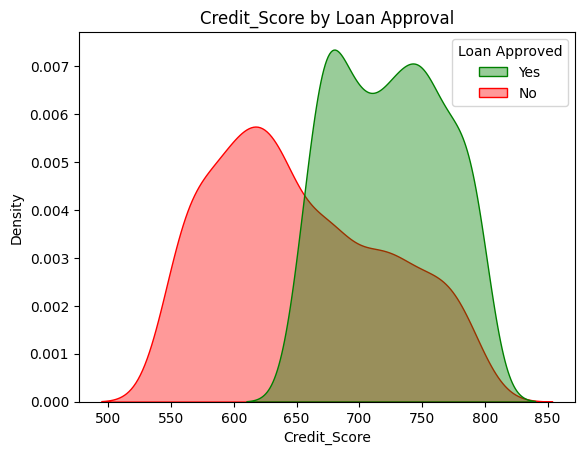

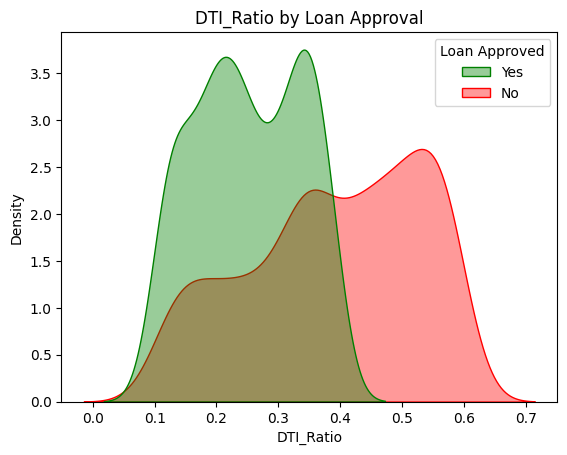

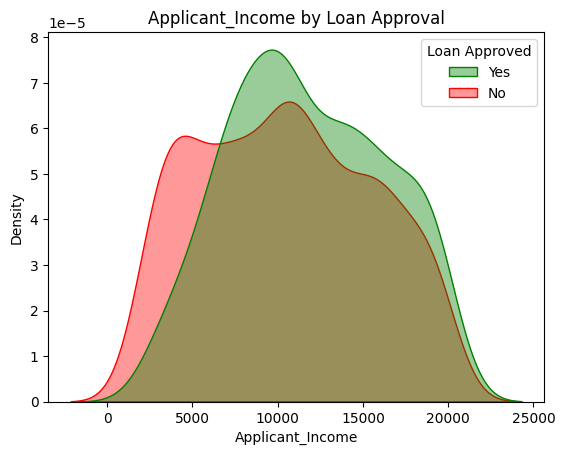

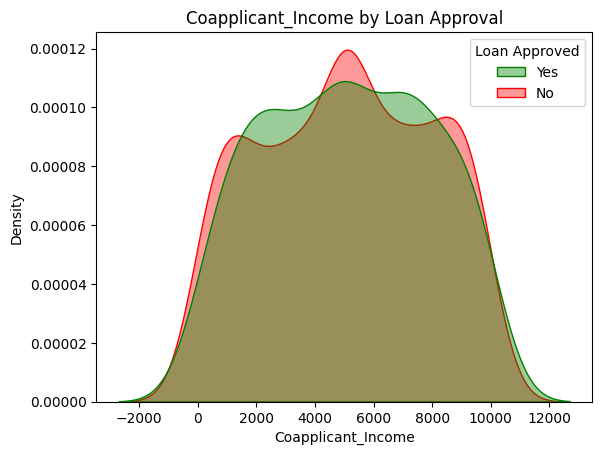

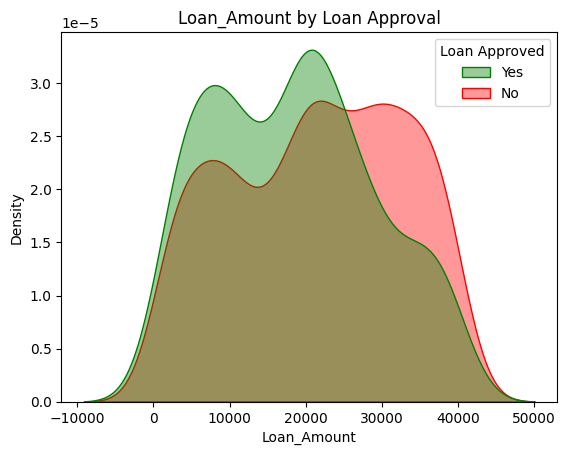

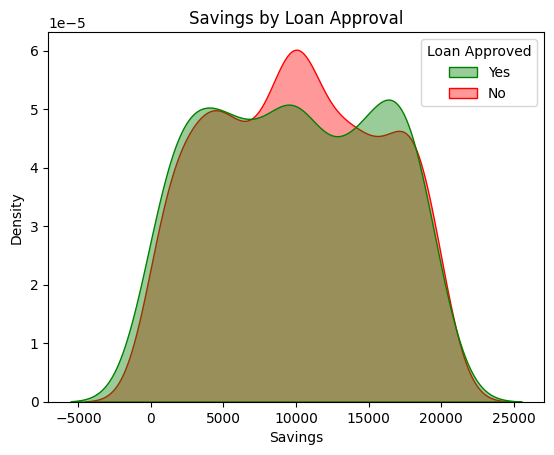

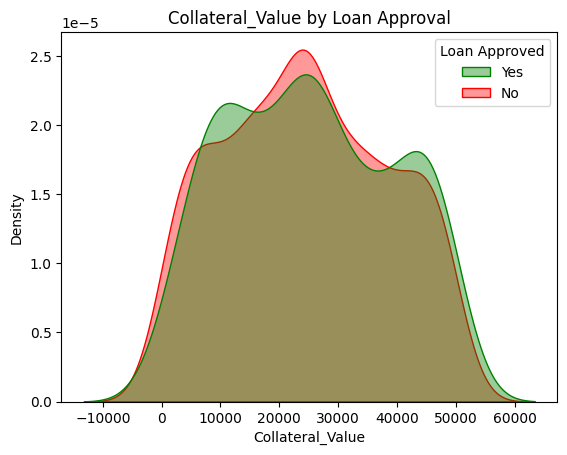

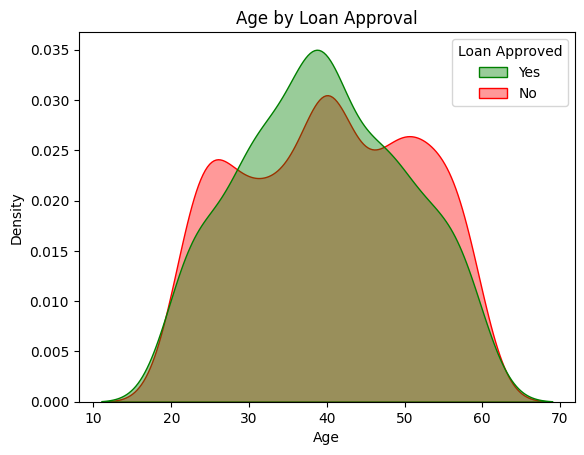

In [12]:
cols = ["Credit_Score", "DTI_Ratio", "Applicant_Income", "Coapplicant_Income",
        "Loan_Amount", "Savings", "Collateral_Value", "Age"]
colors = {"Yes": "green", "No": "red"}

for col in cols:
    ax = sns.kdeplot(data=df, x=col, hue="Loan_Approved",
                     hue_order=["Yes", "No"], palette=colors,
                     fill=True, common_norm=False, alpha=0.4)
    sns.move_legend(ax, "upper right", title="Loan Approved")
    plt.title(f"{col} by Loan Approval")
    plt.show()

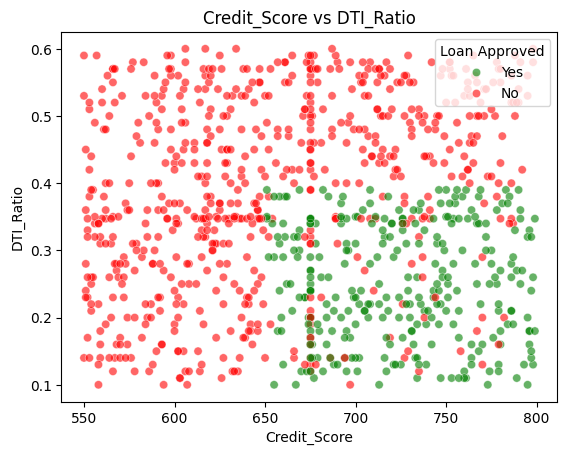

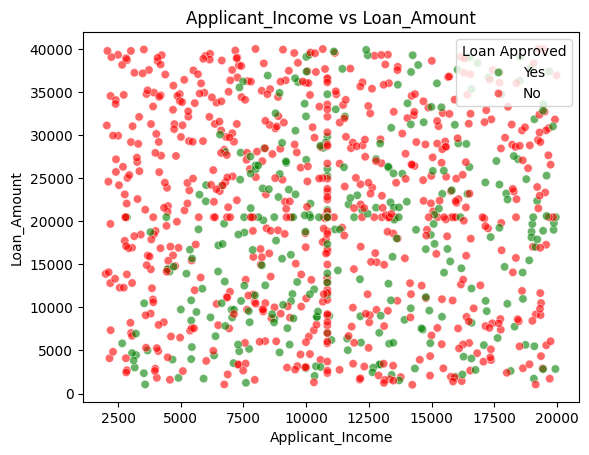

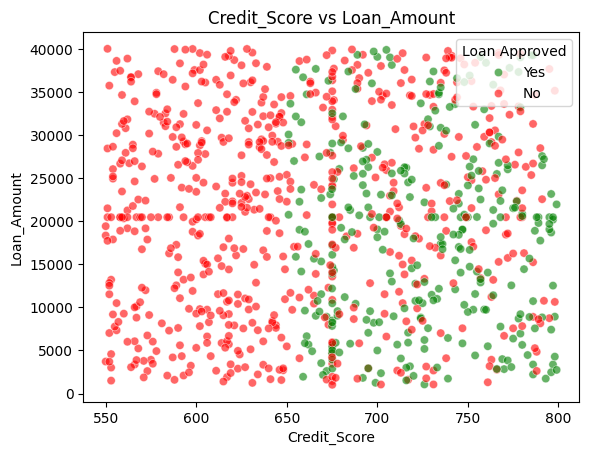

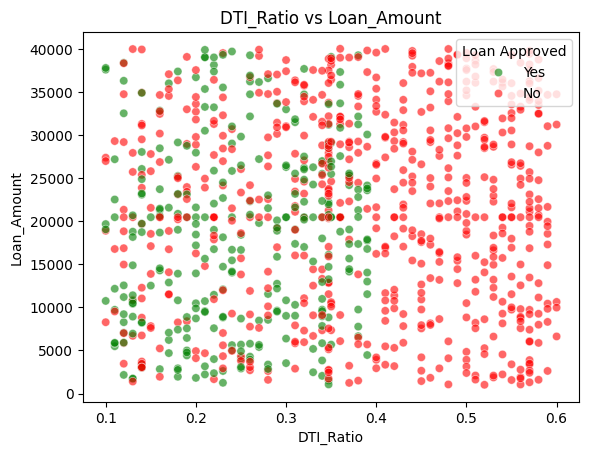

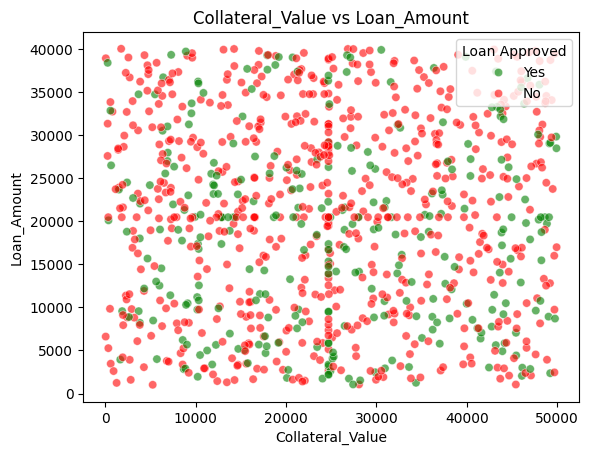

In [13]:
pairs = [("Credit_Score", "DTI_Ratio"),
         ("Applicant_Income", "Loan_Amount"),
         ("Credit_Score", "Loan_Amount"),
         ("DTI_Ratio", "Loan_Amount"),
         ("Collateral_Value", "Loan_Amount")]

for x, y in pairs:
    ax = sns.scatterplot(data=df, x=x, y=y, hue="Loan_Approved",
                         hue_order=["Yes", "No"], palette=colors, alpha=0.6)
    sns.move_legend(ax, "upper right", title="Loan Approved")
    plt.title(f"{x} vs {y}")
    plt.show()

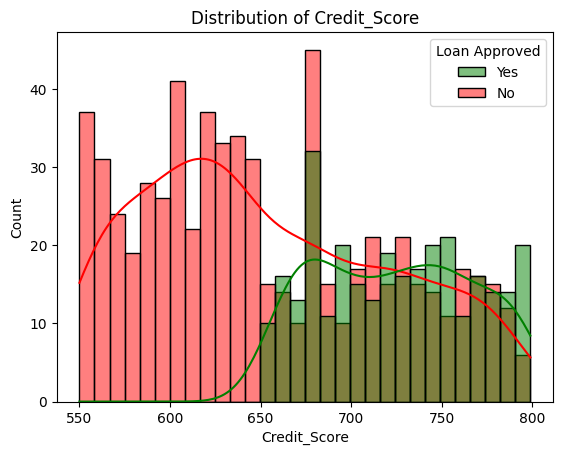

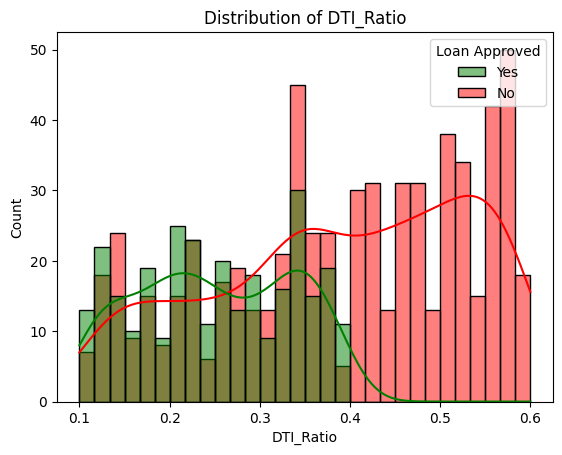

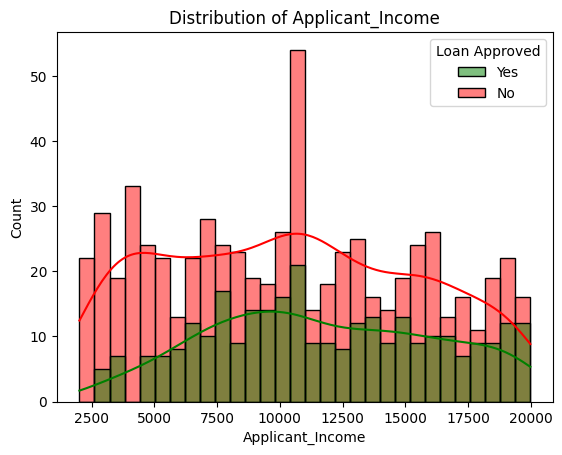

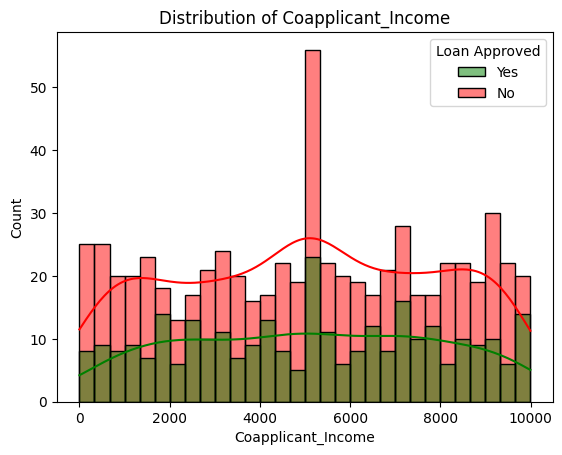

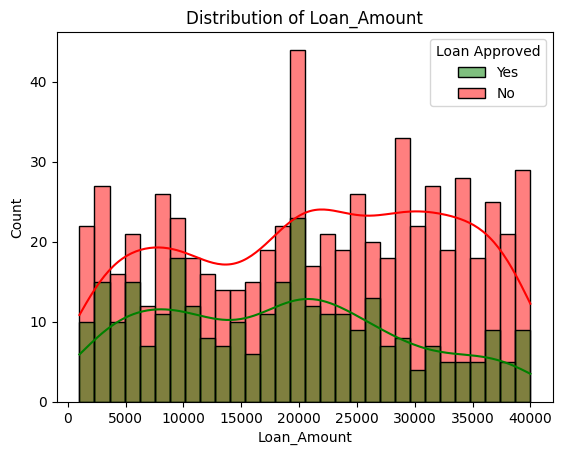

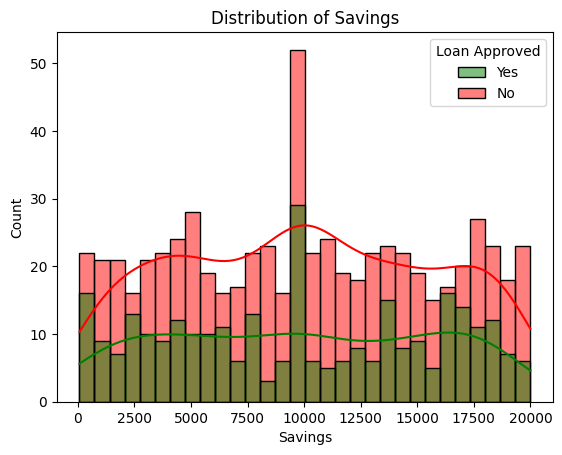

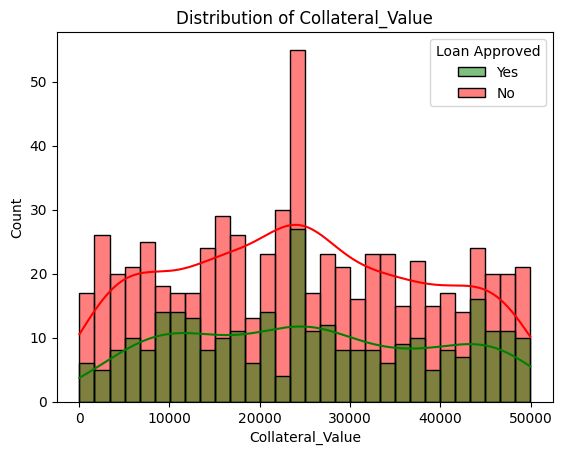

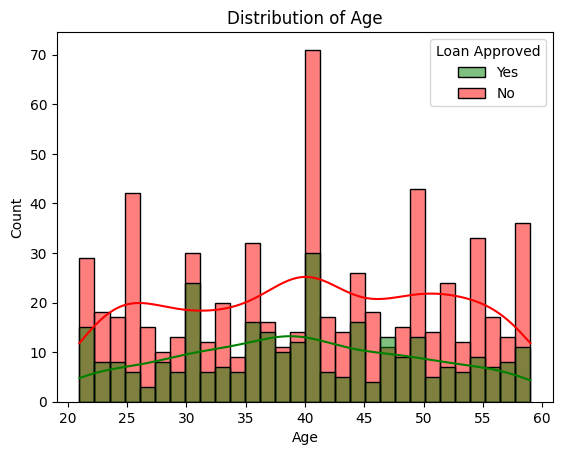

In [16]:
cols = ["Credit_Score", "DTI_Ratio", "Applicant_Income", "Coapplicant_Income",
        "Loan_Amount", "Savings", "Collateral_Value", "Age"]
df_plot = df.dropna(subset=["Loan_Approved"])

colors = {"Yes": "green", "No": "red"}

for col in cols:
    ax = sns.histplot(data=df_plot, x=col, hue="Loan_Approved",
                      hue_order=["Yes", "No"], palette=colors,
                      bins=30, kde=True, alpha=0.5)
    sns.move_legend(ax, "upper right", title="Loan Approved")
    plt.title(f"Distribution of {col}")
    plt.show()

In [17]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

le = LabelEncoder()
df["Education_Level"] = le.fit_transform(df["Education_Level"])
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])   # No = 0, Yes = 1

cols = ["Employment_Status", "Marital_Status", "Loan_Purpose", "Property_Area", "Gender", "Employer_Category"]
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
encoded = ohe.fit_transform(df[cols])
encoded_df = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(cols), index=df.index)
df = pd.concat([df.drop(columns=cols), encoded_df], axis=1)

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 950 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 950 non-null    float64
 1   Coapplicant_Income               950 non-null    float64
 2   Age                              950 non-null    float64
 3   Dependents                       950 non-null    float64
 4   Credit_Score                     950 non-null    float64
 5   Existing_Loans                   950 non-null    float64
 6   DTI_Ratio                        950 non-null    float64
 7   Savings                          950 non-null    float64
 8   Collateral_Value                 950 non-null    float64
 9   Loan_Amount                      950 non-null    float64
 10  Loan_Term                        950 non-null    float64
 11  Education_Level                  950 non-null    int64  
 12  Loan_Approved              

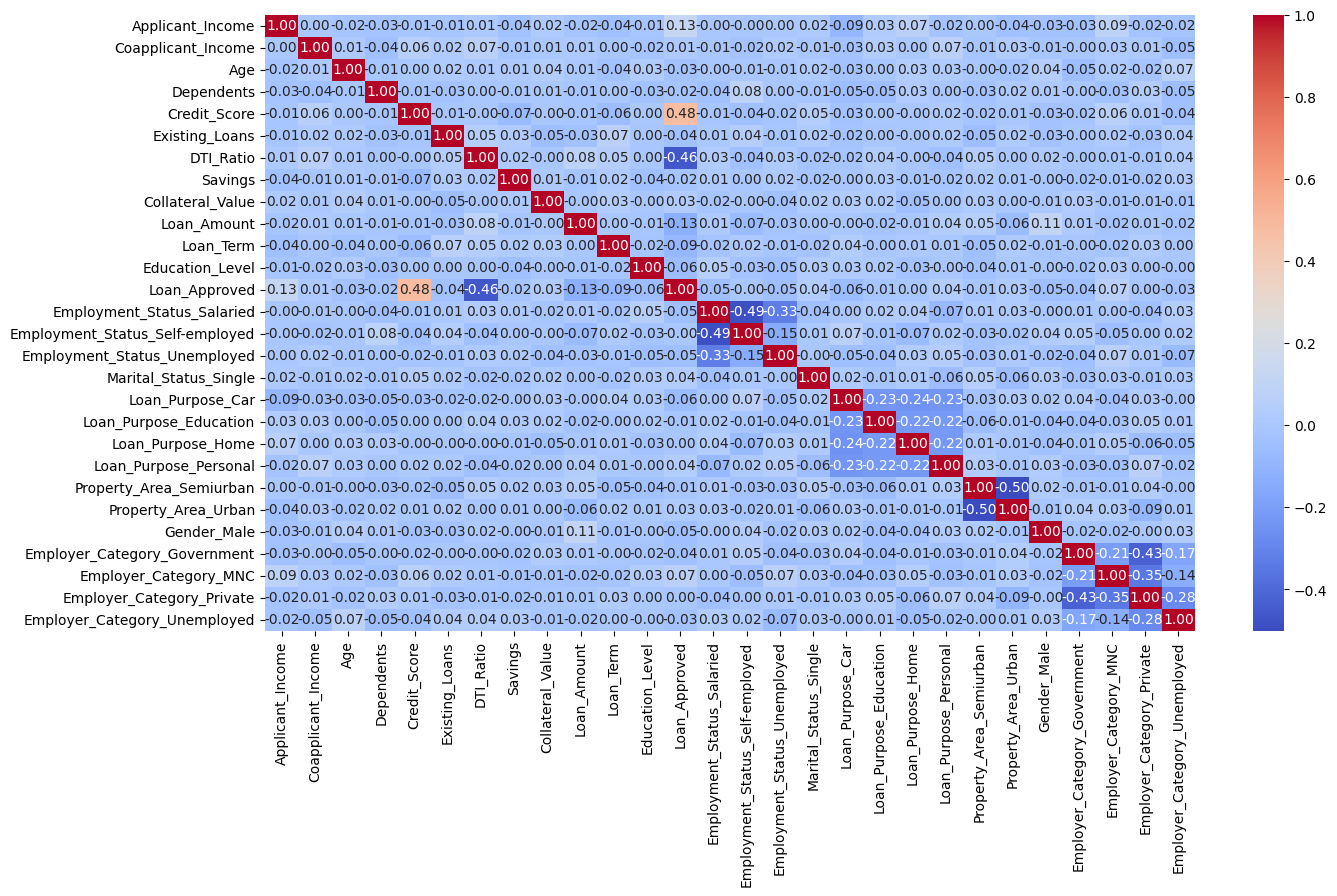

In [18]:
corr_matrix = df.corr()

plt.figure(figsize=(15, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()


In [19]:
corr_matrix["Loan_Approved"].sort_values(ascending=False)

,Loan_Approved
Loan_Approved,1.000000
Credit_Score,0.476911
Applicant_Income,0.125010
Employer_Category_MNC,0.073448
Marital_Status_Single,0.037586
Loan_Purpose_Personal,0.035519
Collateral_Value,0.027350
Property_Area_Urban,0.025731
Coapplicant_Income,0.009127
Loan_Purpose_Home,0.003108


In [20]:
# MODEL TRAINING

from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

In [21]:
# function to train all models and return the scores
def train_models(X_train, X_test, y_train, y_test):
    models = {
        'Logistic Regression': LogisticRegression(max_iter=1000),
        'KNN': KNeighborsClassifier(),
        'Naive Bayes': GaussianNB(),
        'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
        'Random Forest': RandomForestClassifier(random_state=42),
        'Gradient Boosting': GradientBoostingClassifier(random_state=42),
        'SVM': SVC(probability=True, random_state=42),
        'XGBoost': XGBClassifier(random_state=42)
    }

    rows = []
    for name, model in models.items():
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        prob = model.predict_proba(X_test)[:, 1]

        rows.append([name,
                     accuracy_score(y_test, pred),
                     precision_score(y_test, pred),
                     recall_score(y_test, pred),
                     f1_score(y_test, pred),
                     roc_auc_score(y_test, prob),
                     cross_val_score(model, X_train, y_train, cv=5, scoring='f1').mean()])

    results = pd.DataFrame(rows, columns=['Model', 'Accuracy', 'Precision', 'Recall',
                                          'F1 Score', 'ROC AUC', 'CV F1'])
    return results.round(3), models

In [22]:
X = df.drop(columns=['Loan_Approved'])
y = df['Loan_Approved']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

results_base, models_base = train_models(X_train_scaled, X_test_scaled, y_train, y_test)
print('Without feature engineering')
print(results_base)

Without feature engineering
                 Model  Accuracy  Precision  Recall  F1 Score  ROC AUC  CV F1
0  Logistic Regression     0.868      0.818   0.750     0.783    0.918  0.773
1                  KNN     0.758      0.625   0.583     0.603    0.778  0.575
2          Naive Bayes     0.863      0.854   0.683     0.759    0.939  0.769
3        Decision Tree     0.953      0.905   0.950     0.927    0.980  0.938
4        Random Forest     0.947      0.903   0.933     0.918    0.981  0.914
5    Gradient Boosting     0.953      0.905   0.950     0.927    0.987  0.930
6                  SVM     0.874      0.833   0.750     0.789    0.940  0.771
7              XGBoost     0.968      0.935   0.967     0.951    0.989  0.922


In [23]:
df["DTI_Ratio_sq"] = df["DTI_Ratio"] ** 2
df["Credit_Score_sq"] = df["Credit_Score"] ** 2

df['Good_Credit'] = (df['Credit_Score'] > 650).astype(int)
df['Low_DTI'] = (df['DTI_Ratio'] <= 0.4).astype(int)

df['Total_Income'] = df['Applicant_Income'] + df['Coapplicant_Income']
df['Loan_to_Income'] = df['Loan_Amount'] / df['Total_Income']
df['EMI'] = df['Loan_Amount'] / df['Loan_Term']
df['EMI_to_Income'] = df['EMI'] / df['Total_Income']
df['Collateral_to_Loan'] = df['Collateral_Value'] / df['Loan_Amount']
df['Savings_to_Loan'] = df['Savings'] / df['Loan_Amount']

df['Applicant_Income'] = np.log1p(df['Applicant_Income'])
df['Coapplicant_Income'] = np.log1p(df['Coapplicant_Income'])
df['Total_Income'] = np.log1p(df['Total_Income'])
df['Loan_Amount'] = np.log1p(df['Loan_Amount'])
df['Savings'] = np.log1p(df['Savings'])
df['Collateral_Value'] = np.log1p(df['Collateral_Value'])

In [24]:
X = df.drop(columns=["Loan_Approved", "Credit_Score", "DTI_Ratio"])
y = df["Loan_Approved"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

results_fe, models = train_models(X_train_scaled, X_test_scaled, y_train, y_test)
print('With feature engineering')
print(results_fe)

With feature engineering
                 Model  Accuracy  Precision  Recall  F1 Score  ROC AUC  CV F1
0  Logistic Regression     0.937      0.853   0.967     0.906    0.975  0.910
1                  KNN     0.900      0.781   0.950     0.857    0.949  0.819
2          Naive Bayes     0.921      0.800   1.000     0.889    0.980  0.895
3        Decision Tree     0.942      0.866   0.967     0.913    0.951  0.939
4        Random Forest     0.958      0.906   0.967     0.935    0.980  0.947
5    Gradient Boosting     0.947      0.891   0.950     0.919    0.985  0.937
6                  SVM     0.942      0.845   1.000     0.916    0.981  0.910
7              XGBoost     0.953      0.892   0.967     0.928    0.989  0.941


                 Model  F1 Before  F1 After  CV F1 Before  CV F1 After  CV F1 Gain
0  Logistic Regression      0.783     0.906         0.773        0.910       0.137
1                  KNN      0.603     0.857         0.575        0.819       0.244
2          Naive Bayes      0.759     0.889         0.769        0.895       0.126
3        Decision Tree      0.927     0.913         0.938        0.939       0.001
4        Random Forest      0.918     0.935         0.914        0.947       0.033
5    Gradient Boosting      0.927     0.919         0.930        0.937       0.007
6                  SVM      0.789     0.916         0.771        0.910       0.139
7              XGBoost      0.951     0.928         0.922        0.941       0.019


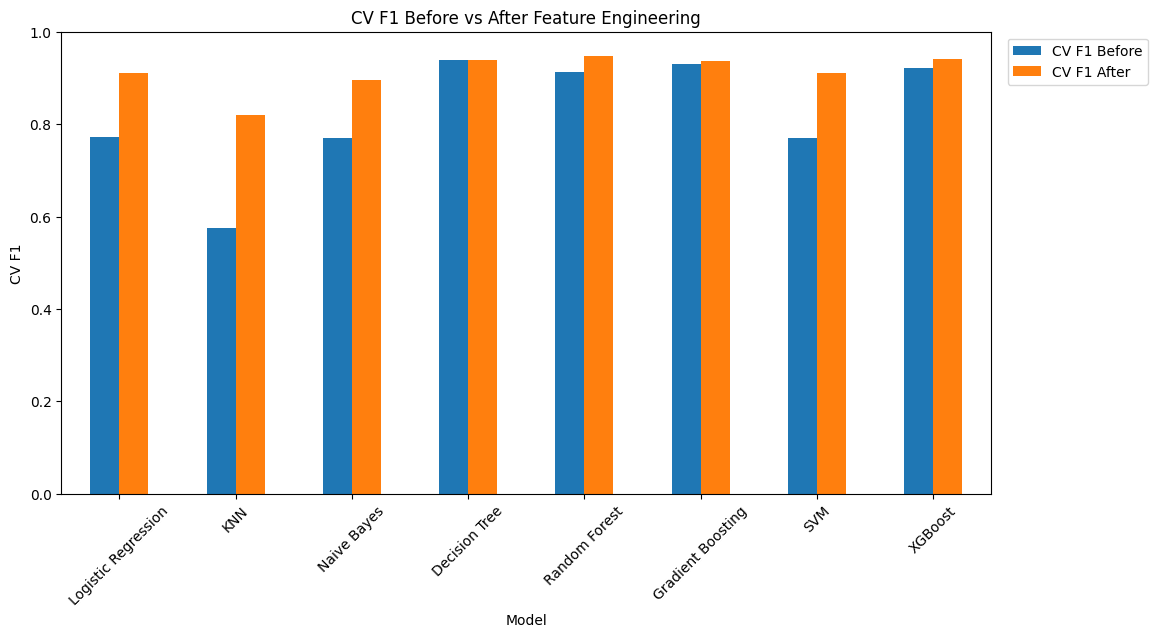

In [25]:
compare = pd.DataFrame({
    'Model': results_base['Model'],
    'F1 Before': results_base['F1 Score'],
    'F1 After': results_fe['F1 Score'],
    'CV F1 Before': results_base['CV F1'],
    'CV F1 After': results_fe['CV F1']
})
compare['CV F1 Gain'] = (compare['CV F1 After'] - compare['CV F1 Before']).round(3)
print(compare)

compare.set_index('Model')[['CV F1 Before', 'CV F1 After']].plot(kind='bar', figsize=(12, 6))
plt.title('CV F1 Before vs After Feature Engineering')
plt.ylabel('CV F1')
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

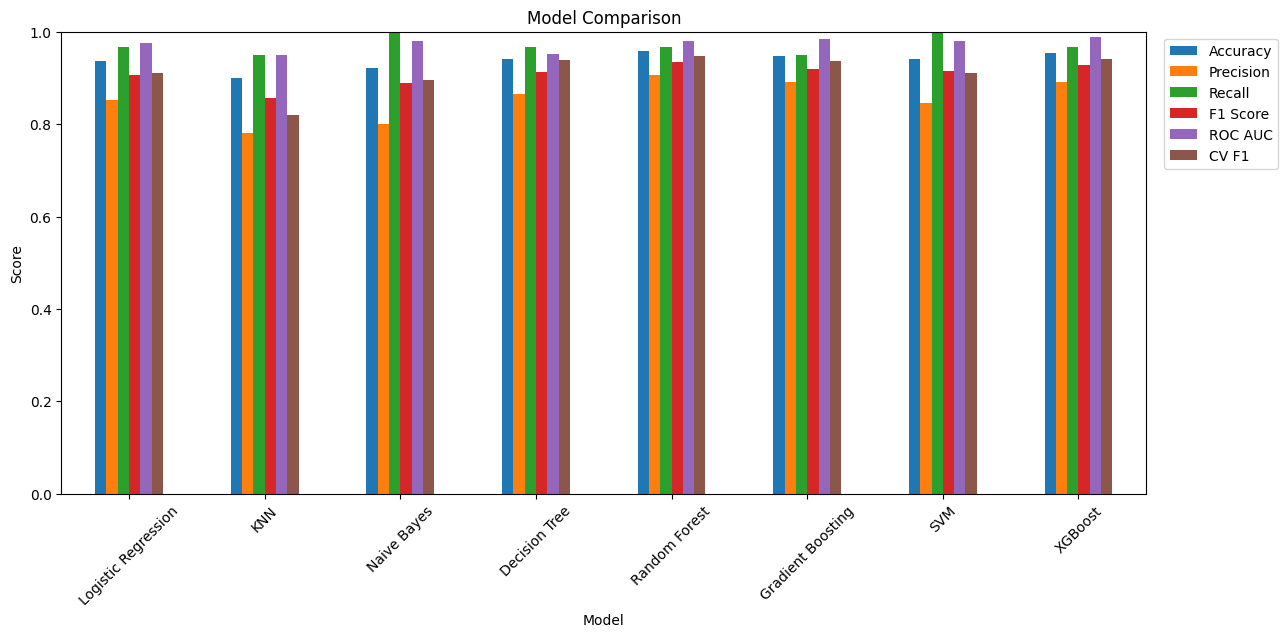

In [26]:
results_fe.set_index('Model').plot(kind='bar', figsize=(14, 6))
plt.title('Model Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

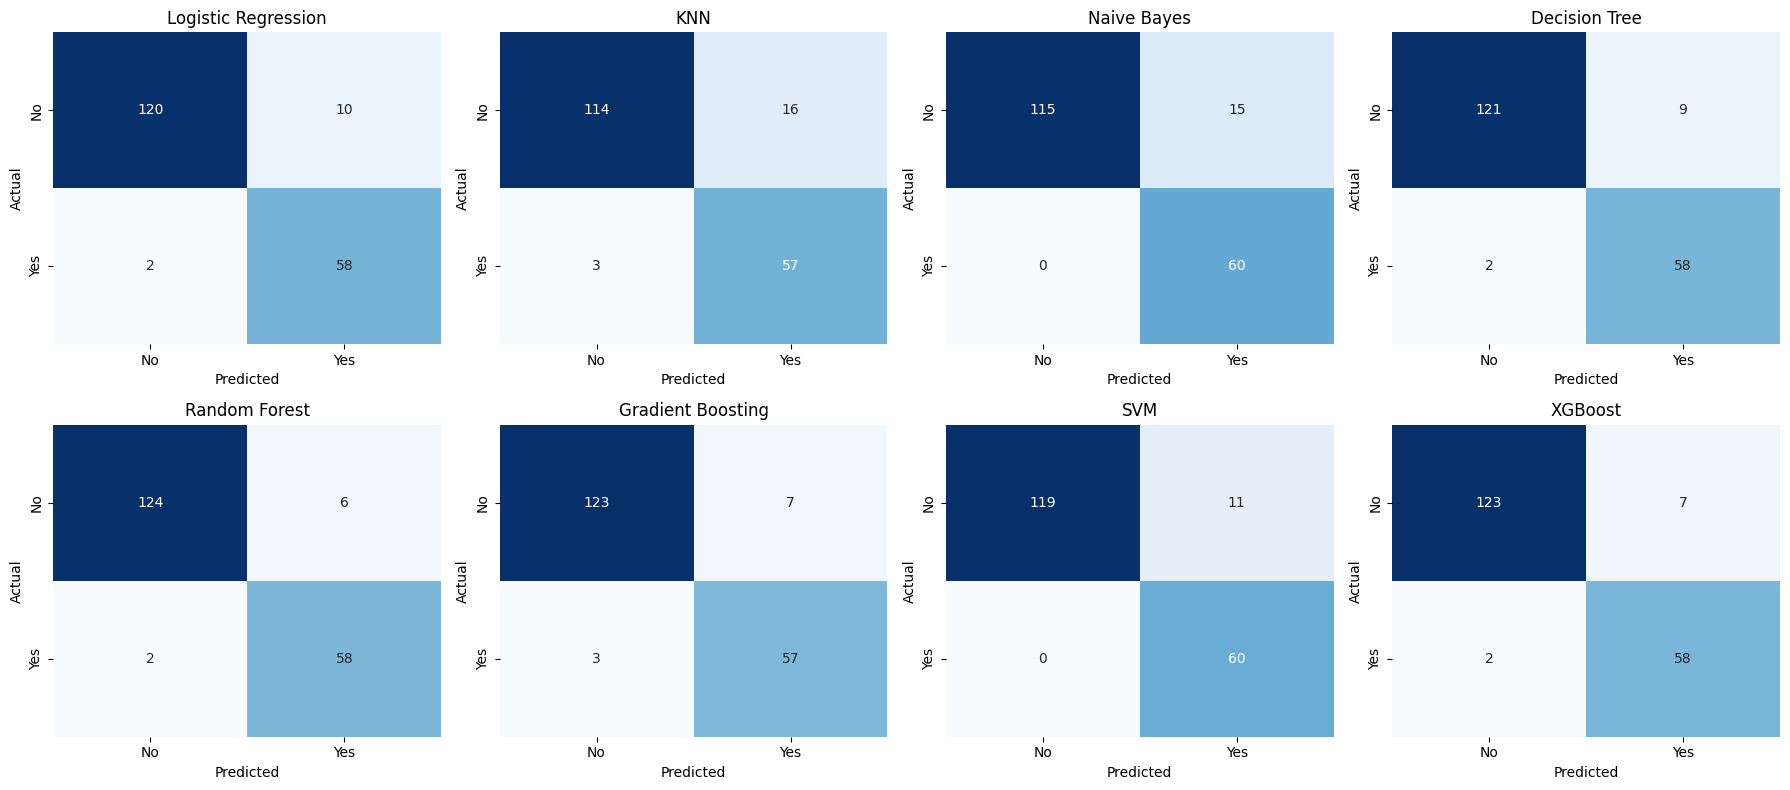

In [27]:
# confusion matrix
plt.figure(figsize=(18, 8))
i = 1
for name, model in models.items():
    pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, pred)
    plt.subplot(2, 4, i)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
    plt.title(name)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    i = i + 1
plt.tight_layout()
plt.show()

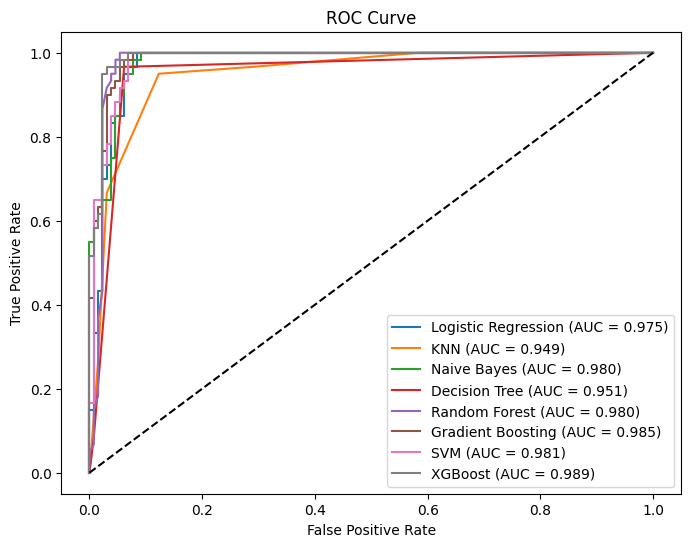

In [28]:
# roc curve
plt.figure(figsize=(8, 6))
for name, model in models.items():
    prob = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

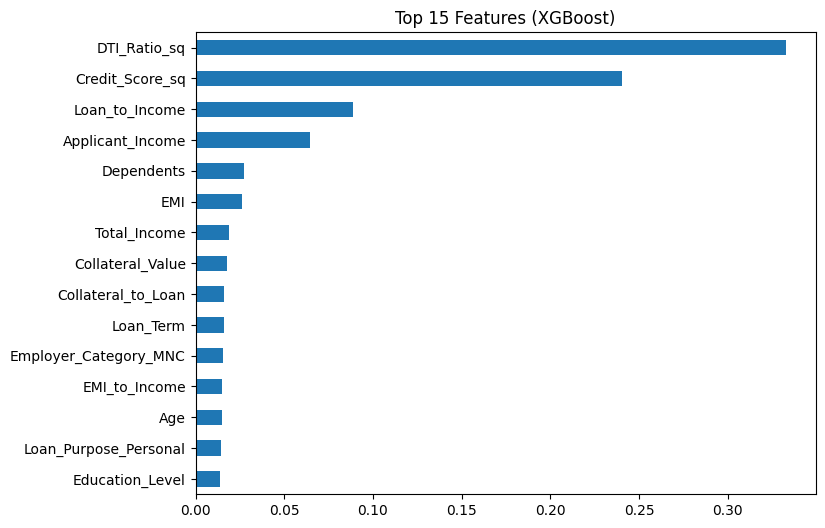

In [29]:
# feature importance
imp = pd.Series(models['XGBoost'].feature_importances_, index=X.columns)
imp.sort_values().tail(15).plot(kind='barh', figsize=(8, 6))
plt.title('Top 15 Features (XGBoost)')
plt.show()

In [30]:
final = results_fe.sort_values('CV F1', ascending=False)
print(final)
print('Best Model:', final.iloc[0]['Model'])

                 Model  Accuracy  Precision  Recall  F1 Score  ROC AUC  CV F1
4        Random Forest     0.958      0.906   0.967     0.935    0.980  0.947
7              XGBoost     0.953      0.892   0.967     0.928    0.989  0.941
3        Decision Tree     0.942      0.866   0.967     0.913    0.951  0.939
5    Gradient Boosting     0.947      0.891   0.950     0.919    0.985  0.937
0  Logistic Regression     0.937      0.853   0.967     0.906    0.975  0.910
6                  SVM     0.942      0.845   1.000     0.916    0.981  0.910
2          Naive Bayes     0.921      0.800   1.000     0.889    0.980  0.895
1                  KNN     0.900      0.781   0.950     0.857    0.949  0.819
Best Model: Random Forest


In [31]:
# HYPERPARAMETER TUNING

rf_params = {'n_estimators': [100, 300], 'max_depth': [None, 5, 10], 'min_samples_leaf': [1, 3, 5]}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_params, cv=5, scoring='f1')
rf_grid.fit(X_train_scaled, y_train)

xgb_params = {'n_estimators': [100, 300], 'max_depth': [3, 5], 'learning_rate': [0.05, 0.1]}
xgb_grid = GridSearchCV(XGBClassifier(random_state=42), xgb_params, cv=5, scoring='f1')
xgb_grid.fit(X_train_scaled, y_train)

tuned = pd.DataFrame({
    'Model': ['Random Forest (tuned)', 'XGBoost (tuned)'],
    'Best Params': [rf_grid.best_params_, xgb_grid.best_params_],
    'CV F1': [rf_grid.best_score_, xgb_grid.best_score_],
    'Test F1': [f1_score(y_test, rf_grid.predict(X_test_scaled)),
                f1_score(y_test, xgb_grid.predict(X_test_scaled))]
}).round(3)
print(tuned.to_string())

                   Model                                                    Best Params  CV F1  Test F1
0  Random Forest (tuned)  {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300}  0.947    0.928
1        XGBoost (tuned)   {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100}  0.946    0.937


In [32]:
rule_pred = X_test['Good_Credit'] * X_test['Low_DTI']
xgb_pred = models['XGBoost'].predict(X_test_scaled)

print('Simple rule')
print('accuracy :', round(accuracy_score(y_test, rule_pred), 3))
print('precision:', round(precision_score(y_test, rule_pred), 3))
print('recall   :', round(recall_score(y_test, rule_pred), 3))
print('f1       :', round(f1_score(y_test, rule_pred), 3))

print('XGBoost')
print('accuracy :', round(accuracy_score(y_test, xgb_pred), 3))
print('precision:', round(precision_score(y_test, xgb_pred), 3))
print('recall   :', round(recall_score(y_test, xgb_pred), 3))
print('f1       :', round(f1_score(y_test, xgb_pred), 3))

Simple rule
accuracy : 0.911
precision: 0.779
recall   : 1.0
f1       : 0.876
XGBoost
accuracy : 0.953
precision: 0.892
recall   : 0.967
f1       : 0.928


In [33]:
X2 = X.drop('Gender_Male', axis=1)
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.2, random_state=42, stratify=y)

score_with = cross_val_score(XGBClassifier(random_state=42), X_train, y_train, cv=5, scoring='f1').mean()
score_without = cross_val_score(XGBClassifier(random_state=42), X2_train, y2_train, cv=5, scoring='f1').mean()

print('CV F1 with gender   :', round(score_with, 3))
print('CV F1 without gender:', round(score_without, 3))

CV F1 with gender   : 0.941
CV F1 without gender: 0.951


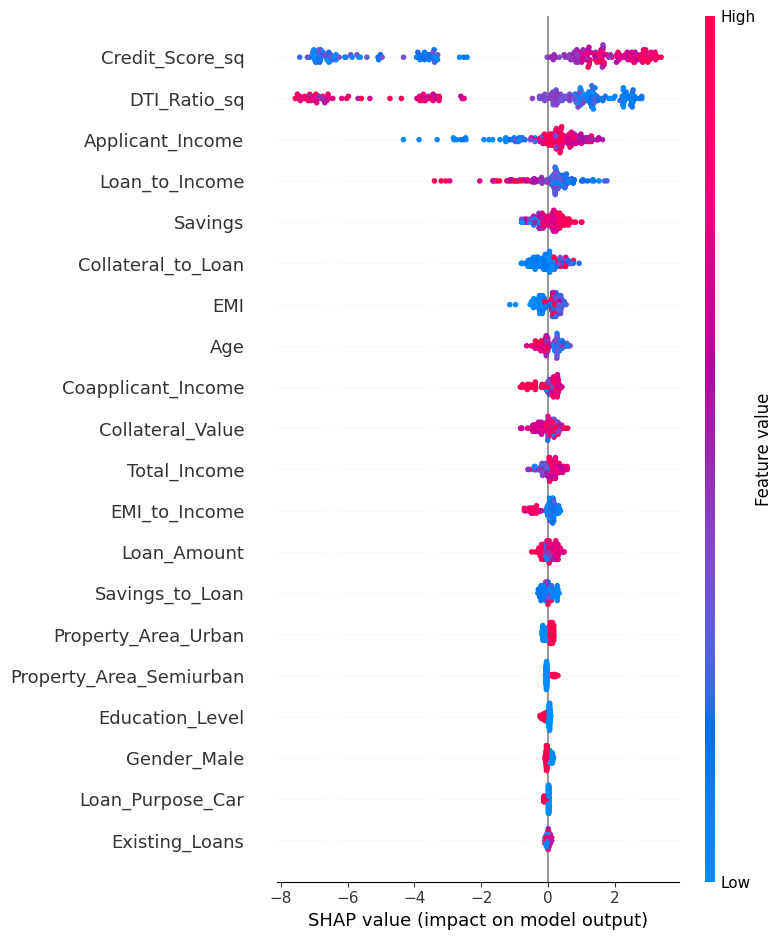

In [34]:
import shap

explainer = shap.TreeExplainer(models['XGBoost'])
shap_values = explainer.shap_values(X_test_scaled)
shap.summary_plot(shap_values, X_test_scaled, feature_names=X.columns)

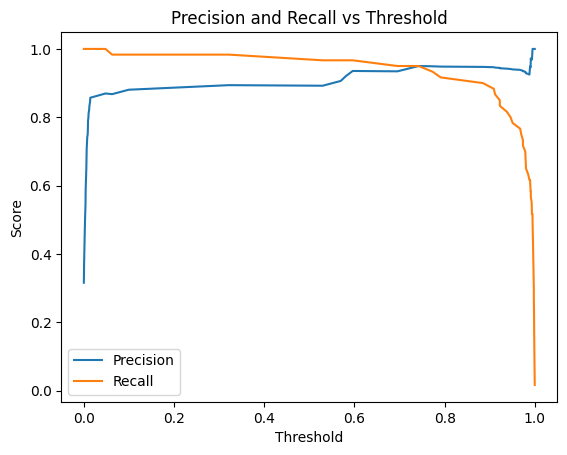

threshold 0.3 : precision 0.894 , recall 0.983
threshold 0.5 : precision 0.892 , recall 0.967
threshold 0.7 : precision 0.95 , recall 0.95


In [35]:
from sklearn.metrics import precision_recall_curve

prob = models['XGBoost'].predict_proba(X_test_scaled)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, prob)

plt.plot(thr, prec[:-1], label='Precision')
plt.plot(thr, rec[:-1], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.show()

for t in [0.3, 0.5, 0.7]:
    pred = (prob >= t).astype(int)
    print('threshold', t, ': precision', round(precision_score(y_test, pred), 3),
          ', recall', round(recall_score(y_test, pred), 3))